# Binary Classification of VPN and NonVPN Network Traffic Using Machine Learning

**Course:** TAM400 — Introduction to Applied Artificial Intelligence and Machine Learning (University West, Sweden)  
**Program:** Bachelor of Science in Computer Engineering (TGDTA)  
**Authors:** Shucayb Ahmed Said and Ayub Ali Barre (Group 17)

---

## Section 1 — Introduction

A **Virtual Private Network (VPN)** encrypts network traffic and routes it through an intermediate server to protect user privacy and secure communication. **NonVPN** traffic travels directly across the network without a VPN tunnel. Because encryption hides packet contents, network management and cybersecurity tools cannot rely on payload inspection alone and instead examine flow-level timing and volume statistics.

In this project, we study **binary classification** of recorded network flows from the ISCXVPN2016 benchmark dataset:
- **NonVPN = 0** (standard network traffic without a VPN tunnel)
- **VPN = 1** (traffic captured through an active VPN connection)

Our goal is to follow a clear, reproducible machine learning workflow—from data cleaning and exploratory data analysis to 10-fold stratified cross-validation and held-out evaluation—comparing three classifiers:
1. **DummyClassifier** (a simple majority-class baseline)
2. **SGDClassifier** (a linear classifier for comparison)
3. **Random Forest** (our selected tree-ensemble classifier)

## Section 2 — Import Libraries and Load Dataset

We use standard Python data science libraries (`numpy`, `pandas`, `matplotlib`, and `scikit-learn`). The code cell below ensures the reference package versions are available when running in Google Colab, imports the required modules, and sets a fixed random seed (`42`) so all splits and model fits are reproducible.

We then load the 15-second flow dataset (`15s.arff`) from our pinned public mirror of the **ISCXVPN2016** dataset (Canadian Institute for Cybersecurity, University of New Brunswick) and verify its SHA-256 checksum to confirm the raw data file is unchanged.

In [1]:
import hashlib
import importlib.metadata
import subprocess
import sys
from io import StringIO
from pathlib import Path
from urllib.request import urlretrieve

# Ensure reference package versions are installed when running in Google Colab
required_versions = {
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "matplotlib": "3.10.7",
    "scipy": "1.14.1",
}
missing_packages = []
for package, version in required_versions.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing_packages.append(f"{package}=={version}")

if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])
    for mod_name in list(sys.modules):
        if mod_name == "sklearn" or mod_name.startswith("sklearn."):
            del sys.modules[mod_name]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

# Clean, consistent academic plot styling
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
NAVY = "#1B365D"
GRAY = "#6C757D"
ACCENT = "#C85A32"

print("Python version:", sys.version.split()[0])
print("Package versions:", {pkg: importlib.metadata.version(pkg) for pkg in required_versions})

Python version: 3.12.4
Package versions: {'scikit-learn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.1.3', 'matplotlib': '3.10.7', 'scipy': '1.14.1'}


In [2]:
# Download the ISCXVPN2016 15-second ARFF dataset if not already present locally
dataset_url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_sha256 = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")

if not data_file.exists():
    urlretrieve(dataset_url, data_file)

actual_sha256 = hashlib.sha256(data_file.read_bytes()).hexdigest()

# Parse ARFF attribute names and data rows
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
data_start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[data_start:])), names=columns)

print(f"SHA-256 checksum ({actual_sha256 == expected_sha256}): {actual_sha256}")
print(f"Raw dataset shape: {df.shape[0]:,} rows and {df.shape[1]} columns")
display(df.head())

SHA-256 checksum (True): 8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563
Raw dataset shape: 18,758 rows and 24 columns


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4,1523088,97590.739583,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4,1517774,87383.785714,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15,1079974,89312.019231,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8,2441990,127659.871795,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10,3042717,133013.359551,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## Section 3 — Data Cleaning

We select nine numerical flow-timing and rate features from the dataset:
1. `duration` — total duration of the flow (stored in microseconds in the raw file)
2. `flowPktsPerSecond` — flow packets per second
3. `flowBytesPerSecond` — flow bytes per second
4. `min_flowiat` — minimum inter-arrival time between packets in the flow
5. `max_flowiat` — maximum inter-arrival time between packets in the flow
6. `mean_flowiat` — mean inter-arrival time between packets in the flow
7. `std_flowiat` — standard deviation of packet inter-arrival times
8. `mean_active` — mean time the flow was actively transmitting before becoming idle
9. `mean_idle` — mean time the flow remained idle between active periods

The original `class1` column contains specific traffic labels (such as `CHAT` or `VPN-CHAT`). Labels starting with `VPN-` are mapped to `1` (**VPN**), and all other labels are mapped to `0` (**NonVPN**).

We apply three cleaning rules before training:
1. **Invalid negative values:** Time durations and traffic rates cannot be negative. The raw feature columns contain `1,240` negative entries, which we replace with `NaN` so they can be imputed using the training median inside each model pipeline.
2. **Exact duplicate rows:** We remove `725` repeated rows where all nine features and the class label are identical.
3. **Conflicting-label rows:** We remove `54` rows that have identical feature values but opposite class labels (`VPN` vs. `NonVPN`), leaving **17,979 clean observations**.

**Methodological note:** Removing conflicting-label rows before splitting uses class labels from the full dataset. While median imputation and scaling are fitted strictly on training data inside each pipeline, we disclose this pre-split conflict filtering as a limitation of the dataset preparation.

In [3]:
features = [
    "duration",
    "flowPktsPerSecond",
    "flowBytesPerSecond",
    "min_flowiat",
    "max_flowiat",
    "mean_flowiat",
    "std_flowiat",
    "mean_active",
    "mean_idle",
]

X_raw = df[features].copy()
y_raw = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

# 1. Replace negative measurements with NaN (missing values)
negative_cells = int((X_raw < 0).sum().sum())
X_raw[X_raw < 0] = np.nan

# 2. Remove exact duplicate (feature + label) rows
clean_df = pd.concat([X_raw, y_raw], axis=1)
rows_before_dedup = len(clean_df)
clean_df = clean_df.drop_duplicates()
exact_duplicates_removed = rows_before_dedup - len(clean_df)

# 3. Remove rows with identical features but conflicting class labels
rows_before_conflict = len(clean_df)
clean_df = clean_df.drop_duplicates(subset=features, keep=False)
conflicting_rows_removed = rows_before_conflict - len(clean_df)

X = clean_df[features]
y = clean_df["vpn"]

cleaning_summary = pd.DataFrame([
    {"Step": "Raw observations loaded", "Count": len(df)},
    {"Step": "Negative feature cells converted to NaN", "Count": negative_cells},
    {"Step": "Exact duplicate rows removed", "Count": exact_duplicates_removed},
    {"Step": "Conflicting-label rows removed", "Count": conflicting_rows_removed},
    {"Step": "Final cleaned observations retained", "Count": len(clean_df)},
])
display(cleaning_summary)

,Step,Count
0,Raw observations loaded,18758
1,Negative feature cells converted to NaN,1240
2,Exact duplicate rows removed,725
3,Conflicting-label rows removed,54
4,Final cleaned observations retained,17979


## Section 4 — Exploratory Data Analysis

To prevent information from the held-out test set from influencing our data exploration, we examine the **training partition (14,383 flows)** created by our stratified 80/20 split (verified in detail in Section 5).

Below we inspect three key characteristics of the training data:
1. **Class balance (Figure 1):** The training set is reasonably balanced, with `6,927` NonVPN flows (`48.16%`) and `7,456` VPN flows (`51.84%`).
2. **Flow duration in seconds (Figure 2):** The raw `duration` column is recorded in microseconds by ISCXFlowMeter, so we divide by `1,000,000` to plot **Flow duration (seconds)**. Because the dataset uses a 15-second capture window target, most flows last 15 seconds or less, while `281` training flows exceed 15 seconds (up to `601.4` seconds), creating a strongly right-skewed distribution.
3. **Linear correlation with the VPN label:** All nine features have weak Pearson correlations with the binary target (ranging from `-0.0670` to `+0.0532`). A small Pearson correlation only indicates a weak *linear* relationship; decision trees can still use non-linear thresholds and feature combinations effectively.

Training flow duration summary (in seconds):


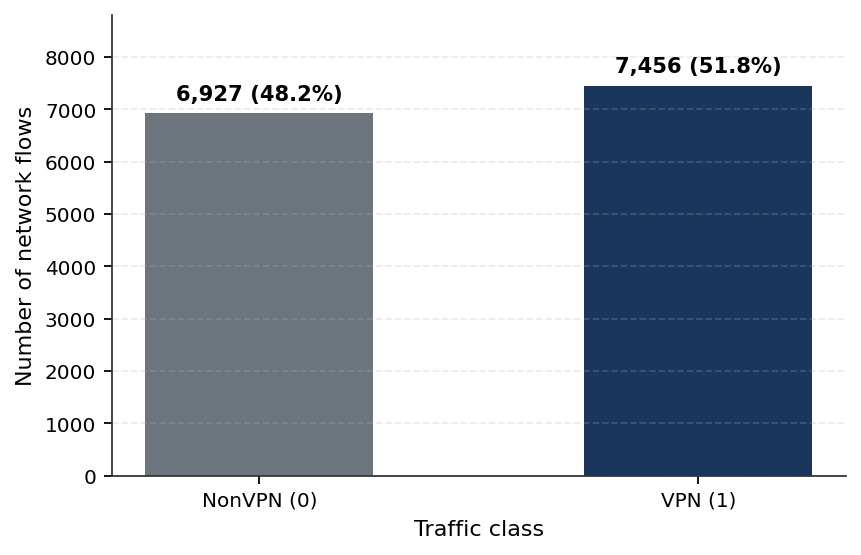

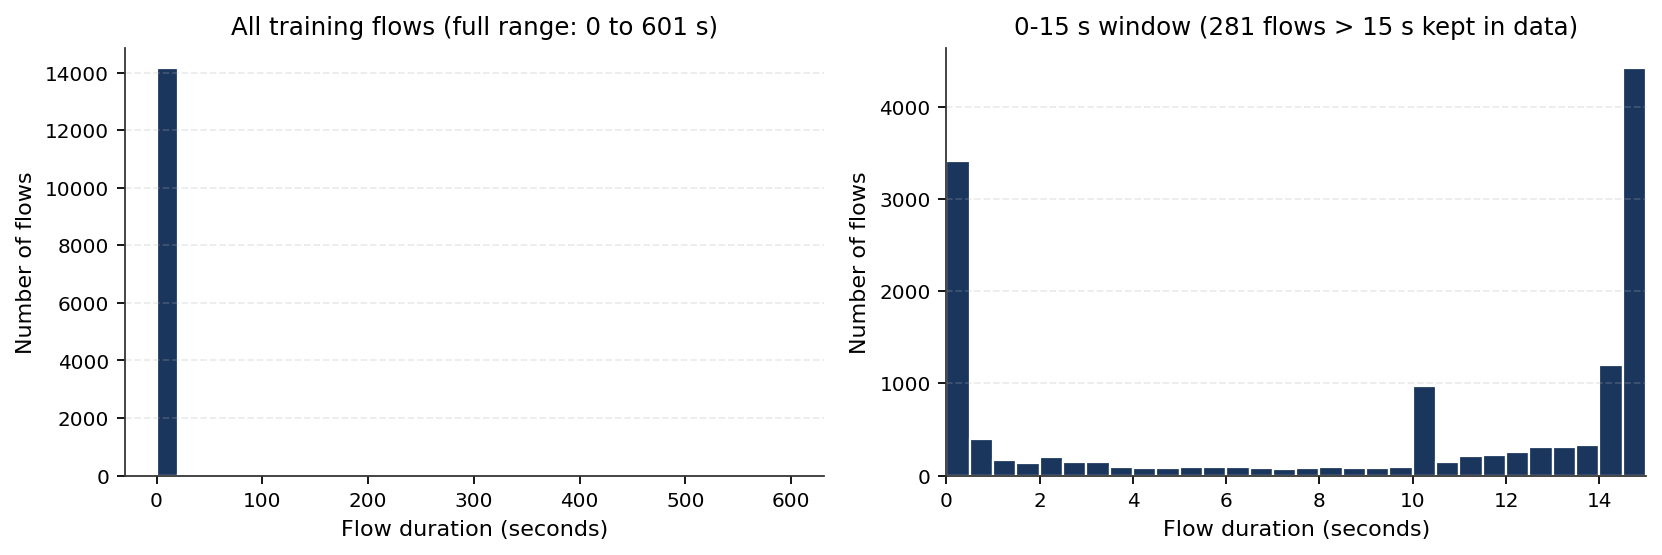

,count,mean,std,min,25%,50%,75%,95%,max
Duration (seconds),14383.0,10.178,14.86,0.0,0.692,11.85,14.96,14.999,601.405


,Feature,Pearson correlation with VPN,Missing values (train)
0,mean_flowiat,0.0532,0
1,min_flowiat,0.0378,136
2,std_flowiat,0.0050,0
3,flowPktsPerSecond,0.0007,0
4,mean_active,-0.0077,0
5,max_flowiat,-0.0133,0
6,mean_idle,-0.0151,0
7,flowBytesPerSecond,-0.0347,0
8,duration,-0.0670,0


In [4]:
# Create the stratified 80/20 split so EDA inspects only the training partition
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Figure 1: Training Class Distribution
class_counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(
    ["NonVPN (0)", "VPN (1)"],
    class_counts.values,
    color=[GRAY, NAVY],
    width=0.52,
    edgecolor="none",
)
ax.set_ylabel("Number of network flows")
ax.set_xlabel("Traffic class")
ax.set_ylim(0, 8800)
ax.grid(axis="y", alpha=0.25, linestyle="--")
for bar, count in zip(bars, class_counts.values):
    pct = 100.0 * count / len(y_train)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 180,
        f"{count:,} ({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

# Figure 2: Flow Duration Histogram in Seconds (Full Range vs. 0-15 Seconds Zoom)
duration_seconds = X_train["duration"].dropna() / 1_000_000
flows_over_15s = int((duration_seconds > 15).sum())

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].hist(duration_seconds, bins=30, color=NAVY, edgecolor="white")
axes[0].set_xlabel("Flow duration (seconds)")
axes[0].set_ylabel("Number of flows")
axes[0].set_title("All training flows (full range: 0 to 601 s)")
axes[0].grid(axis="y", alpha=0.25, linestyle="--")

axes[1].hist(duration_seconds, bins=np.linspace(0, 15, 31), color=NAVY, edgecolor="white")
axes[1].set_xlabel("Flow duration (seconds)")
axes[1].set_ylabel("Number of flows")
axes[1].set_xlim(0, 15)
axes[1].set_title(f"0-15 s window ({flows_over_15s} flows > 15 s kept in data)")
axes[1].grid(axis="y", alpha=0.25, linestyle="--")
plt.tight_layout()
plt.show()

# Summary statistics for duration (in seconds) and Pearson correlation with VPN label
duration_stats = duration_seconds.describe(percentiles=[0.25, 0.50, 0.75, 0.95]).round(3)
print("Training flow duration summary (in seconds):")
display(duration_stats.to_frame(name="Duration (seconds)").T)

corr_series = X_train.assign(vpn=y_train).corr(numeric_only=True)["vpn"].drop("vpn").sort_values(ascending=False)
corr_table = corr_series.rename_axis("Feature").reset_index(name="Pearson correlation with VPN")
corr_table["Missing values (train)"] = [int(X_train[f].isna().sum()) for f in corr_table["Feature"]]
display(corr_table.round(4))

## Section 5 — Train/Test Split

We divide the `17,979` cleaned observations into two separate subsets using a **stratified 80/20 split** (`random_state=42`):
- **Training set (80% — 14,383 flows):** Used to fit preprocessing parameters (median imputation and feature scaling), run 10-fold cross-validation, and train the final model.
- **Test set (20% — 3,596 flows):** Held out from model training and cross-validation to evaluate final performance.

Stratification keeps the proportion of VPN flows (`51.84%`) identical in both partitions. We also verify that no identical feature row appears in both the training and test sets.

In [5]:
# Verify split sizes, index checksum, and zero exact feature overlap
expected_split_hash = "bbb0deef12ebaf2233e4c561f752c7ab8b0fc44f4b1de2073b4919e7812f064f"
actual_split_hash = hashlib.sha256(X_test.index.to_numpy().tobytes()).hexdigest()

train_row_hashes = pd.util.hash_pandas_object(X_train, index=False)
test_row_hashes = pd.util.hash_pandas_object(X_test, index=False)
exact_overlap = int(train_row_hashes.isin(test_row_hashes).sum())

split_summary = pd.DataFrame([
    {
        "Partition": "Training set (80%)",
        "Total flows": len(X_train),
        "NonVPN (0)": int((y_train == 0).sum()),
        "VPN (1)": int((y_train == 1).sum()),
        "VPN share (%)": round(100.0 * y_train.mean(), 2),
    },
    {
        "Partition": "Test set (20%)",
        "Total flows": len(X_test),
        "NonVPN (0)": int((y_test == 0).sum()),
        "VPN (1)": int((y_test == 1).sum()),
        "VPN share (%)": round(100.0 * y_test.mean(), 2),
    },
])
print(f"Split index SHA-256 verified: {actual_split_hash}")
print(f"Exact feature-vector overlap between train and test: {exact_overlap}")
display(split_summary)

Split index SHA-256 verified: bbb0deef12ebaf2233e4c561f752c7ab8b0fc44f4b1de2073b4919e7812f064f
Exact feature-vector overlap between train and test: 0


,Partition,Total flows,NonVPN (0),VPN (1),VPN share (%)
0,Training set (80%),14383,6927,7456,51.84
1,Test set (20%),3596,1732,1864,51.84


## Section 6 — Define the Three Classifiers

We compare three supervised classification models wrapped in scikit-learn `Pipeline` objects so that median imputation (and standardization for `SGDClassifier`) is fitted strictly on the training rows in every fold:

1. **DummyClassifier:** DummyClassifier is a simple baseline that always predicts the majority class. We used it to see whether our machine learning models perform better than a basic prediction strategy.
2. **SGDClassifier:** SGDClassifier is a linear machine learning model. We used it to compare a simpler approach with Random Forest.
3. **Random Forest:** Random Forest combines predictions from many decision trees. It can learn more complex relationships between the network-flow features and the VPN labels.

The hyperparameters for our **Random Forest** classifier (`n_estimators=200`, `criterion="entropy"`, `max_depth=14`, `min_samples_leaf=4`, `min_samples_split=10`, `max_features=5`, `max_samples=0.7`, `bootstrap=True`, `random_state=42`) were selected during earlier training-only hyperparameter tuning to reduce tree complexity and narrow the overfitting gap.

In [6]:
rf_classifier = RandomForestClassifier(
    n_estimators=200,
    criterion="entropy",
    max_depth=14,
    min_samples_leaf=4,
    min_samples_split=10,
    max_features=5,
    max_samples=0.7,
    bootstrap=True,
    random_state=SEED,
)

models = {
    "DummyClassifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "SGDClassifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SGDClassifier(random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", rf_classifier),
    ]),
}

print("Selected Random Forest parameters:")
for param_name in [
    "n_estimators", "criterion", "max_depth", "min_samples_leaf",
    "min_samples_split", "max_features", "max_samples", "bootstrap", "random_state"
]:
    print(f"  {param_name}: {rf_classifier.get_params()[param_name]}")

Selected Random Forest parameters:
  n_estimators: 200
  criterion: entropy
  max_depth: 14
  min_samples_leaf: 4
  min_samples_split: 10
  max_features: 5
  max_samples: 0.7
  bootstrap: True
  random_state: 42


## Section 7 — Ten-Fold Cross-Validation

To evaluate how well each classifier generalizes without touching the test set, we use **10-fold stratified cross-validation** (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`) on the `14,383` training flows.

In 10-fold cross-validation, the training set is divided into 10 equal-sized folds with the same class ratio. Each model is trained 10 times—each time using 9 folds for training and the remaining 1 fold for validation. We focus on **VPN F1** (the harmonic mean of VPN precision and VPN recall, with `VPN = 1` as the positive class) because `DummyClassifier` achieves `100%` VPN recall simply by predicting `VPN` for every flow while having low precision (`51.84%`).

We also record the **paired training–validation F1 gap**, defined as the mean across the 10 folds of:
$$\text{Paired F1 Gap} = \text{Fold Training VPN F1} - \text{Fold Validation VPN F1}$$
This measures how much higher the model scores on the folds it was trained on compared with the unseen validation folds.

In [7]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}

comparison_rows = []
cv_results_by_model = {}
fitted_full_models = {}

for name, pipeline in models.items():
    cv_scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv10,
        scoring=scoring,
        return_train_score=True,
        error_score="raise",
    )
    cv_results_by_model[name] = cv_scores

    # Fit on all 14,383 training rows to record full-training Accuracy and VPN F1
    full_fit = clone(pipeline).fit(X_train, y_train)
    fitted_full_models[name] = full_fit
    train_predictions = full_fit.predict(X_train)

    paired_f1_gaps = cv_scores["train_f1"] - cv_scores["test_f1"]

    comparison_rows.append({
        "Model": name,
        "Training Accuracy": float(accuracy_score(y_train, train_predictions)),
        "Training VPN F1": float(f1_score(y_train, train_predictions, pos_label=1, zero_division=0)),
        "Mean Fold-Training VPN F1": float(cv_scores["train_f1"].mean()),
        "Validation Accuracy": float(cv_scores["test_accuracy"].mean()),
        "Validation VPN Precision": float(cv_scores["test_precision"].mean()),
        "Validation VPN Recall": float(cv_scores["test_recall"].mean()),
        "Mean Validation VPN F1": float(cv_scores["test_f1"].mean()),
        "Validation F1 SD": float(cv_scores["test_f1"].std()),
        "Paired Train-Val F1 Gap": float(paired_f1_gaps.mean()),
    })

comparison_table = pd.DataFrame(comparison_rows)
print("10-fold stratified cross-validation completed successfully for all three models.")

10-fold stratified cross-validation completed successfully for all three models.


## Section 8 — Model Comparison

The table and charts below compare our three classifiers across the same 10 stratified folds:
- **DummyClassifier** achieves a validation accuracy of `51.84%` and a validation VPN F1 of `0.6828` because it predicts every flow as `VPN` (`100%` recall, `51.84%` precision).
- **SGDClassifier** reaches a slightly higher validation accuracy (`59.22%`), but its validation VPN F1 (`0.6369`) is lower than the majority-class baseline and varies more across folds (`SD = 0.0326`), showing that a simple linear decision boundary does not separate the nine flow features well.
- **Random Forest** performs substantially better, achieving `93.81%` (`93.8052%`) full-training accuracy, `0.9410` (`0.940966`) full-training VPN F1, `88.81%` mean validation accuracy, `0.8941` (`0.894053`) mean 10-fold validation VPN F1 (`SD = 0.0087`), and a paired training–validation F1 gap of `0.0466` (`0.046553`).

,Model,Training Accuracy,Training VPN F1,Mean Fold-Training VPN F1,Validation Accuracy,Validation VPN Precision,Validation VPN Recall,Mean Validation VPN F1,Validation F1 SD,Paired Train-Val F1 Gap
0,DummyClassifier,0.5184,0.6828,0.6828,0.5184,0.5184,1.0000,0.6828,0.0003,0.0000
1,SGDClassifier,0.5893,0.6420,0.6361,0.5922,0.5907,0.6939,0.6369,0.0326,-0.0008
2,Random Forest,0.9381,0.9410,0.9406,0.8881,0.8772,0.9112,0.8941,0.0087,0.0466


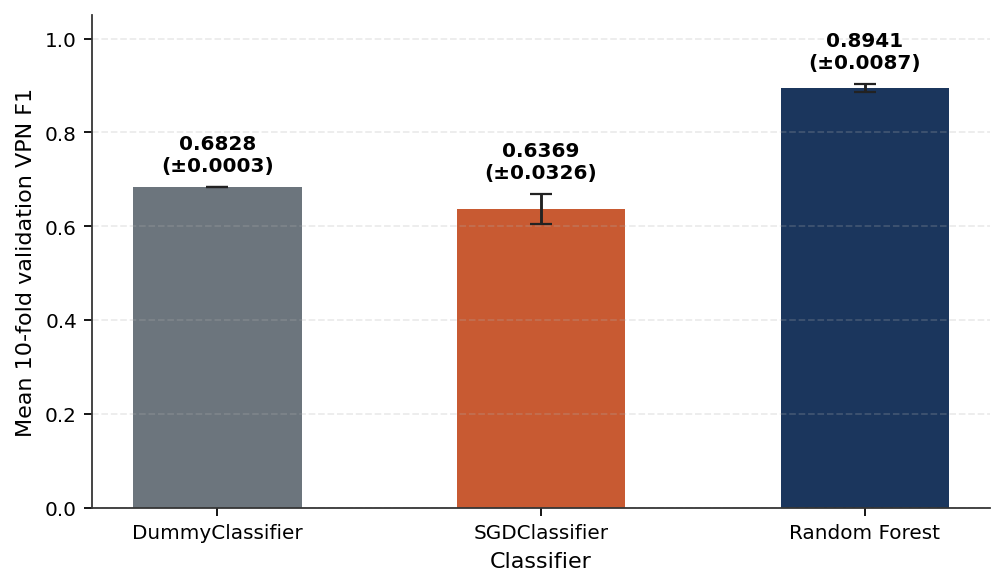

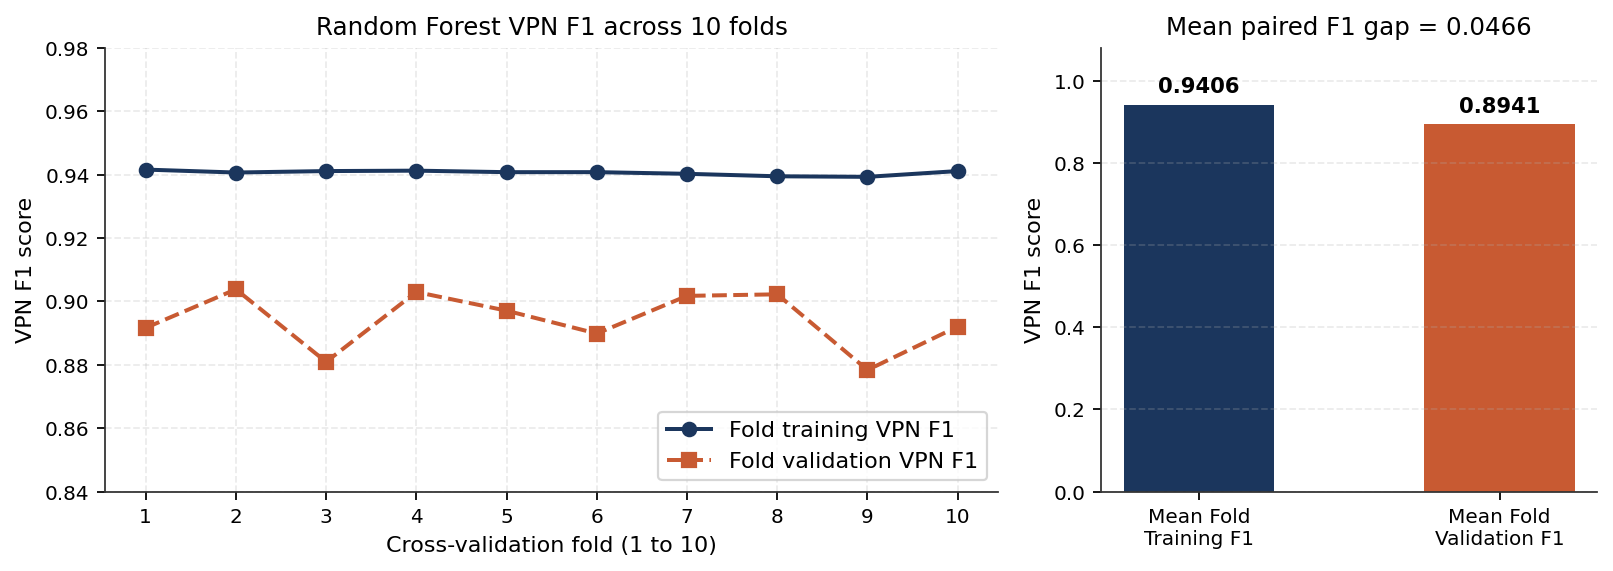

In [8]:
display(comparison_table.round(4))

# Figure 3: Three-Classifier Validation VPN F1 Comparison
fig, ax = plt.subplots(figsize=(6.4, 3.8))
bar_colors = [GRAY, ACCENT, NAVY]
bars = ax.bar(
    comparison_table["Model"],
    comparison_table["Mean Validation VPN F1"],
    yerr=comparison_table["Validation F1 SD"],
    capsize=5,
    color=bar_colors,
    width=0.52,
    error_kw={"elinewidth": 1.3, "ecolor": "#222222"},
)
ax.set_ylabel("Mean 10-fold validation VPN F1")
ax.set_xlabel("Classifier")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25, linestyle="--")
for bar, mean_val, sd_val in zip(
    bars, comparison_table["Mean Validation VPN F1"], comparison_table["Validation F1 SD"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        mean_val + sd_val + 0.025,
        f"{mean_val:.4f}\n(±{sd_val:.4f})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

# Figure 4: Random Forest Training vs. Validation VPN F1 Across the 10 Folds
rf_cv = cv_results_by_model["Random Forest"]
fold_numbers = np.arange(1, 11)
rf_train_f1_mean = float(rf_cv["train_f1"].mean())
rf_val_f1_mean = float(rf_cv["test_f1"].mean())
rf_gap_mean = rf_train_f1_mean - rf_val_f1_mean

fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.7), gridspec_kw={"width_ratios": [1.8, 1.0]})

axes[0].plot(fold_numbers, rf_cv["train_f1"], "o-", color=NAVY, linewidth=1.8, label="Fold training VPN F1")
axes[0].plot(fold_numbers, rf_cv["test_f1"], "s--", color=ACCENT, linewidth=1.8, label="Fold validation VPN F1")
axes[0].set_xticks(fold_numbers)
axes[0].set_xlabel("Cross-validation fold (1 to 10)")
axes[0].set_ylabel("VPN F1 score")
axes[0].set_ylim(0.84, 0.98)
axes[0].set_title("Random Forest VPN F1 across 10 folds")
axes[0].grid(alpha=0.25, linestyle="--")
axes[0].legend(loc="lower right", frameon=True)

summary_bars = axes[1].bar(
    ["Mean Fold\nTraining F1", "Mean Fold\nValidation F1"],
    [rf_train_f1_mean, rf_val_f1_mean],
    color=[NAVY, ACCENT],
    width=0.5,
)
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("VPN F1 score")
axes[1].set_title(f"Mean paired F1 gap = {rf_gap_mean:.4f}")
axes[1].grid(axis="y", alpha=0.25, linestyle="--")
for bar, val in zip(summary_bars, [rf_train_f1_mean, rf_val_f1_mean]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.02,
        f"{val:.4f}",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

## Section 9 — Final Random Forest Evaluation

We now evaluate our selected **Random Forest** pipeline (fitted on all `14,383` training observations) on the held-out `3,596` test observations.

**Important evaluation disclosure:** Because this 20% test partition was previously inspected during earlier project development, we report these measurements as a **Reused development-test evaluation** rather than an untouched independent test. No test scores were used to adjust the model parameters or classification threshold.

In [9]:
rf_final_pipeline = fitted_full_models["Random Forest"]

# Predict class labels and VPN probabilities on the held-out test set
y_train_pred = rf_final_pipeline.predict(X_train)
y_test_pred = rf_final_pipeline.predict(X_test)
vpn_class_index = list(rf_final_pipeline.classes_).index(1)
y_test_prob = rf_final_pipeline.predict_proba(X_test)[:, vpn_class_index]

rf_row = comparison_table.loc[comparison_table["Model"] == "Random Forest"].iloc[0]

final_metrics = {
    "Training Accuracy": float(accuracy_score(y_train, y_train_pred)),
    "Training VPN F1": float(f1_score(y_train, y_train_pred, pos_label=1)),
    "Mean 10-Fold Validation VPN F1": float(rf_row["Mean Validation VPN F1"]),
    "Paired Training-Validation F1 Gap": float(rf_row["Paired Train-Val F1 Gap"]),
    "Test Accuracy": float(accuracy_score(y_test, y_test_pred)),
    "Test VPN Precision": float(precision_score(y_test, y_test_pred, pos_label=1)),
    "Test VPN Recall": float(recall_score(y_test, y_test_pred, pos_label=1)),
    "Test VPN F1": float(f1_score(y_test, y_test_pred, pos_label=1)),
    "Test ROC-AUC": float(roc_auc_score(y_test, y_test_prob)),
}

final_metrics_table = pd.DataFrame([
    {"Metric": "Training Accuracy", "Value": f"{final_metrics['Training Accuracy'] * 100:.4f}%", "Decimal": round(final_metrics["Training Accuracy"], 6)},
    {"Metric": "Training VPN F1", "Value": f"{final_metrics['Training VPN F1']:.6f}", "Decimal": round(final_metrics["Training VPN F1"], 6)},
    {"Metric": "Mean 10-Fold Validation VPN F1", "Value": f"{final_metrics['Mean 10-Fold Validation VPN F1']:.6f}", "Decimal": round(final_metrics["Mean 10-Fold Validation VPN F1"], 6)},
    {"Metric": "Paired Training-Validation F1 Gap", "Value": f"{final_metrics['Paired Training-Validation F1 Gap']:.6f}", "Decimal": round(final_metrics["Paired Training-Validation F1 Gap"], 6)},
    {"Metric": "Test Accuracy (reused development-test)", "Value": f"{final_metrics['Test Accuracy'] * 100:.4f}%", "Decimal": round(final_metrics["Test Accuracy"], 6)},
    {"Metric": "Test VPN Precision", "Value": f"{final_metrics['Test VPN Precision']:.6f}", "Decimal": round(final_metrics["Test VPN Precision"], 6)},
    {"Metric": "Test VPN Recall", "Value": f"{final_metrics['Test VPN Recall']:.6f}", "Decimal": round(final_metrics["Test VPN Recall"], 6)},
    {"Metric": "Test VPN F1", "Value": f"{final_metrics['Test VPN F1']:.6f}", "Decimal": round(final_metrics["Test VPN F1"], 6)},
    {"Metric": "Test ROC-AUC", "Value": f"{final_metrics['Test ROC-AUC']:.6f}", "Decimal": round(final_metrics["Test ROC-AUC"], 6)},
])
print("Evaluation status: Reused development-test evaluation (not an independent untouched test)")
display(final_metrics_table)

Evaluation status: Reused development-test evaluation (not an independent untouched test)


,Metric,Value,Decimal
0,Training Accuracy,93.8052%,0.938052
1,Training VPN F1,0.940966,0.940966
2,Mean 10-Fold Validation VPN F1,0.894053,0.894053
3,Paired Training-Validation F1 Gap,0.046553,0.046553
4,Test Accuracy (reused development-test),89.2937%,0.892937
5,Test VPN Precision,0.879036,0.879036
6,Test VPN Recall,0.920064,0.920064
7,Test VPN F1,0.899083,0.899083
8,Test ROC-AUC,0.964009,0.964009


## Section 10 — Confusion Matrix

The confusion matrix (`[[1496, 236], [149, 1715]]`) breaks down the `3,596` test predictions into four outcomes (with actual classes in rows and predicted classes in columns):
- **True Negatives (TN = 1,496):** NonVPN flows correctly classified as NonVPN.
- **False Positives (FP = 236):** NonVPN flows incorrectly flagged as VPN (false VPN alarms).
- **False Negatives (FN = 149):** VPN flows incorrectly classified as NonVPN (missed VPN flows).
- **True Positives (TP = 1,715):** VPN flows correctly classified as VPN.

Overall, the Random Forest correctly classifies `3,211` of the `3,596` flows (`89.2937%`, or `89.29%` test accuracy). It misses fewer VPN flows (`149` false negatives, giving `0.920064` or `92.01%` recall) than the number of false VPN alarms it raises on NonVPN traffic (`236` false positives, giving `0.879036` or `87.90%` precision), yielding a test VPN F1 score of `0.899083` (`0.8991`) and a ROC-AUC of `0.964009` (`0.9640`).

,Predicted NonVPN (0),Predicted VPN (1)
Actual NonVPN (0),1496,236
Actual VPN (1),149,1715


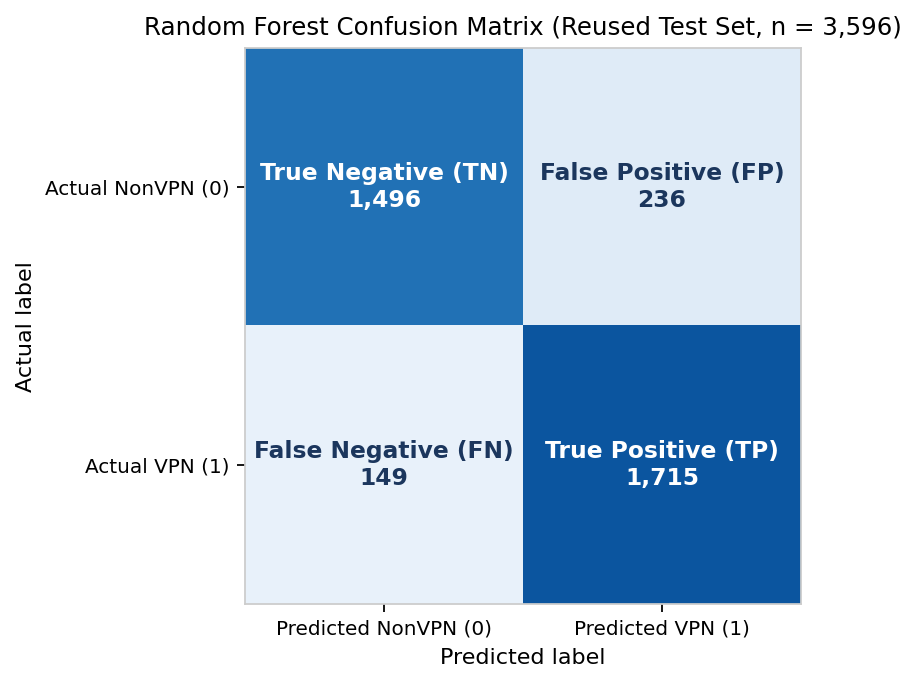

In [10]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
tn, fp, fn, tp = (int(v) for v in cm.ravel())

cm_table = pd.DataFrame(
    cm,
    index=["Actual NonVPN (0)", "Actual VPN (1)"],
    columns=["Predicted NonVPN (0)", "Predicted VPN (1)"],
)
display(cm_table)

# Figure 5: Random Forest Confusion Matrix (Reused Development-Test Evaluation)
fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=2000)

cell_labels = [
    [f"True Negative (TN)\n{tn:,}", f"False Positive (FP)\n{fp:,}"],
    [f"False Negative (FN)\n{fn:,}", f"True Positive (TP)\n{tp:,}"],
]
for i in range(2):
    for j in range(2):
        text_color = "white" if cm[i, j] > 1000 else "#1B365D"
        ax.text(
            j,
            i,
            cell_labels[i][j],
            ha="center",
            va="center",
            color=text_color,
            fontsize=10.5,
            fontweight="bold",
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted NonVPN (0)", "Predicted VPN (1)"])
ax.set_yticklabels(["Actual NonVPN (0)", "Actual VPN (1)"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Random Forest Confusion Matrix (Reused Test Set, n = 3,596)")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#CCCCCC")
plt.tight_layout()
plt.show()

## Section 11 — Discussion

### Model Comparison
Comparing the three classifiers highlights why non-linear tree ensembles are well suited for tabular network-flow statistics:
- **DummyClassifier** (`0.6828` validation VPN F1, `51.84%` validation accuracy) predicts every flow as `VPN`. This shows why recall alone (`100%`) is misleading and why F1 and accuracy must be considered together.
- **SGDClassifier** (`0.6369` validation VPN F1, `59.22%` validation accuracy) performs poorly because individual timing and rate features have very weak linear correlations with the VPN label (`|r| <= 0.067`).
- **Random Forest** (`0.894053` mean 10-fold validation VPN F1, `88.81%` validation accuracy, `0.899083` test VPN F1, `89.2937%` test accuracy, `0.879036` test VPN precision, `0.920064` test VPN recall, and `0.964009` ROC-AUC) captures non-linear thresholds and interactions across packet inter-arrival times and flow rates.

### Overfitting and Regularization Trade-off
In our earlier archived tuning experiments, an unregularized default Random Forest achieved nearly `100%` training F1 (`0.9999`) and `0.9016` validation VPN F1, resulting in a paired training–validation F1 gap of `0.0984`. By restricting maximum tree depth (`max_depth=14`), requiring larger leaf and split sample sizes (`min_samples_leaf=4`, `min_samples_split=10`), and subsampling `70%` of training rows per tree (`max_samples=0.7`), our selected **Random Forest** reduced the paired training–validation F1 gap by **52.7%** (from `0.0984` in the archived default model down to `0.046553`, or `0.0466`).

However, two important points must be noted:
1. **Overfitting is reduced, not eliminated:** The selected Random Forest still scores higher on its training data (`93.8052%` full-training accuracy and `0.940966` full-training VPN F1; `0.940606` mean fold-training VPN F1) than on unseen validation folds (`0.894053` mean validation VPN F1).
2. **Regularization involves a trade-off:** Narrowing the overfitting gap slightly lowered validation and test F1 compared with the unregularized historical forest. A smaller gap provides simpler trees and more realistic training scores, but does not prove higher predictive accuracy.

### Comparison with the Historical Reference Execution
When executing the exact same pipeline and hyperparameters in Google Colab, the Random Forest metrics differ slightly in the fourth decimal place from the historical reference run (`89.2937%` vs. `89.3215%` test accuracy; `0.899083` vs. `0.899371` test VPN F1; `0.894053` vs. `0.893824` mean 10-fold validation VPN F1; `0.046553` vs. `0.046692` paired F1 gap; and `93.8052%` vs. `93.7635%` training accuracy).

Our diagnostic investigation confirmed that the raw `15s.arff` file (SHA-256 `8b12e8c0...04f7c1563`), the `17,979` cleaned observations, the stratified 80/20 train/test split indices (SHA-256 `bbb0deef...12f064f`), and the fitted training median imputer statistics are **identical** across both executions. On the `3,596`-flow test set, the difference between the historical confusion matrix (`[[1496, 236], [148, 1716]]`) and the current Google Colab confusion matrix (`[[1496, 236], [149, 1715]]`) is **a single borderline VPN flow** (test observation `#1698`, whose predicted VPN probability lies within `0.0004` of the `0.50` classification threshold). Because `RandomForestClassifier` evaluates node splits using Shannon entropy (`criterion="entropy"`, which calls the C math library `log2` function) and interacts with NumPy/pandas C-extensions loaded in memory when the Google Colab kernel starts, tiny floating-point rounding differences ($10^{-16}$) at near-tied candidate splits across the 200 trees shift that single borderline flow from `1` (`VPN`) to `0` (`NonVPN`). Both executions confirm the exact same scientific conclusion.

### Methodological Limitations
1. **Reused development-test partition:** The 20% test set (`3,596` flows) was inspected during earlier project iterations, so it is a reused development-test evaluation rather than a fresh, untouched benchmark.
2. **Pre-split conflict removal:** Removing the `54` conflicting-label rows before splitting depended on labels across the full dataset.
3. **Unknown capture sessions:** The ARFF dataset does not include session or capture IDs, meaning closely related flows from the same network session may appear in both training and validation splits.
4. **Historical traffic:** ISCXVPN2016 was recorded in 2016 and may not reflect modern VPN protocols or current application traffic patterns.

## Section 12 — Conclusion

In this project, we implemented and verified a complete binary classification workflow to distinguish **VPN** and **NonVPN** network flows using nine numerical flow-timing and rate features from the **ISCXVPN2016** dataset (`17,979` cleaned flows).

Across 10-fold stratified cross-validation on the `14,383` training flows, our selected **Random Forest** classifier (`0.894053` mean validation VPN F1, `93.8052%` training accuracy, and `0.940966` training VPN F1) clearly outperformed both the majority-class **DummyClassifier** (`0.6828` validation VPN F1) and the linear **SGDClassifier** (`0.6369` validation VPN F1). On the held-out `3,596`-flow reused development-test partition (`[[1496, 236], [149, 1715]]`), the Random Forest achieved **89.2937% accuracy** (`89.29%`), **0.899083 VPN F1** (`0.879036` precision, `0.920064` recall), and **0.964009 ROC-AUC**. While regularization cut the historical training–validation F1 gap in half (`0.046553`), moderate overfitting remains, and future work should evaluate the model on newly captured, session-separated network traffic.

### Acknowledgment of Generative AI Assistance
In accordance with TAM400 course guidelines, we acknowledge that generative AI tools (ChatGPT, OpenAI Codex, and Google Antigravity/Gemini) were used to assist with Python code organization, debugging, local execution, figure formatting, and drafting and editing explanations for clarity. The student authors are responsible for reviewing the code and results, verifying the notebook execution, and understanding and explaining the final submission.

### References
1. G. Draper-Gil, A. H. Lashkari, M. S. I. Mamun, and A. A. Ghorbani, "Characterization of Encrypted and VPN Traffic Using Time-Related Features," in *Proc. 2nd Int. Conf. Information Systems Security and Privacy (ICISSP)*, Rome, Italy, 2016, pp. 407–414, doi: 10.5220/0005740704070414.
2. Canadian Institute for Cybersecurity (CIC), "VPN-nonVPN dataset (ISCXVPN2016)," University of New Brunswick. [Online]. Available: https://www.unb.ca/cic/datasets/vpn.html
3. F. Pedregosa *et al.*, "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011. [Online]. Available: https://scikit-learn.org/stable/
4. S. A. Said and A. A. Barre, "VPN-NonVPN-Classification-project (TAM400 Group 17)," GitHub repository, 2026. [Online]. Available: https://github.com/SAS2005/VPN-NonVPN-Classification-project